# DBMS Fundamentals: Query Processing and Optimization

> **Who is this for?** Learners who know basic SQL and relational algebra and want to know what happens between pressing Enter on a query
> and getting rows back, and why the same query can take 5 ms or 5 minutes. It is also exam/interview revision for the query processing and
> optimization chapters of a DBMS course.
>
> **What you will learn**
> - The pipeline: **parsing → translation to relational algebra → optimization → evaluation plan → execution** (with a tiny parser you build)
> - **Selection** algorithms and their costs; **external merge sort** (implemented: run generation and (M−1)-way merging)
> - Five **join algorithms** implemented and benchmarked: nested-loop, block nested-loop, index nested-loop, sort-merge, (Grace) hash join,
>   with their cost formulas in block I/Os, all checked against pandas
> - **Projection / duplicate elimination** and **aggregation**; **materialization vs. pipelining** (the iterator model)
> - **Heuristic optimization**: equivalence rules, pushing selections and projections down, expression trees before and after
> - **Cost-based optimization**: statistics, selectivity estimation, **histograms**, and **System R dynamic programming** for join order
> - Reading real plans with SQLite's `EXPLAIN QUERY PLAN` and **rewriting a slow query**
>
> **Prerequisites:** [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb), [`../01_sql/01_sql_fundamentals.ipynb`](../01_sql/01_sql_fundamentals.ipynb),
> [`06_recovery_and_storage.ipynb`](06_recovery_and_storage.ipynb) (blocks and files) and [`07_indexing_b_trees_and_hashing.ipynb`](07_indexing_b_trees_and_hashing.ipynb) (indexes).
> Relational algebra (σ select, π project, ⋈ join, × Cartesian product) is used throughout; it is introduced earlier in this module.
>
> **Time needed:** about 3 hours (the code runs in about a minute).
>
> **Runs on:** CPU only, no API key, no internet. Python standard library, numpy, pandas, matplotlib.
>
> **Optional track:** part of the *university-level fundamentals track*; recommended for BS/MS AI students and interview prep.

### Contents
1. The query processing pipeline (and a tiny SQL → relational algebra translator)
2. Measuring cost: block transfers and seeks
3. Selection algorithms
4. External merge sort
5. Join algorithms: implemented, verified, benchmarked
6. Projection, duplicate elimination and aggregation
7. Materialization vs. pipelining
8. Heuristic optimization: equivalence rules and pushing operators down
9. Cost-based optimization: statistics, selectivity, histograms, join ordering with dynamic programming
10. Real plans in SQLite and rewriting a slow query
11. How this connects to modern AI
12. Recap, practice problems, further reading

## Explained simply

When you write SQL you only say **what** you want, not **how** to get it.
The database turns your question into a step-by-step plan, considers many possible plans, estimates the cost of each, and runs the cheapest.
The difference between a good and a bad plan can be milliseconds versus hours on the same data.
Two big ideas do most of the work: **throw away rows you do not need as early as possible**, and **match rows between tables with a clever method**
(like sorting or hashing) instead of comparing every pair.

- **Everyday example 1:** a satnav. You give the destination; it compares routes using traffic information (statistics) and picks the fastest.
- **Everyday example 2:** matching socks after laundry. Comparing every sock with every other sock is slow; first sorting them into piles by colour (hashing) is fast.
- **Everyday example 3:** packing for a trip. You first remove what you will not need, then pack: filtering early makes everything after it lighter.

**Tiny example.** A school has 1,000 students and 1,000 exam results to match by roll number. Comparing every student with every result is
1,000 × 1,000 = **1,000,000** comparisons. Putting the results into 100 boxes by the last two digits of the roll number and only comparing within the matching box
needs about 1,000 × 10 = **10,000** comparisons: 100 times less work for the same answer.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Query optimizer | picks the cheapest way to answer your question | every SQL database, Spark, DuckDB, Polars lazy queries |
| Hash join | match rows by first sorting them into buckets | joining features from several tables to build an ML training set |
| Push filters down | drop unneeded rows before the expensive steps | data pipelines, and filtering metadata before a vector search |

In [1]:
import math, random, re, time, heapq, itertools, sqlite3
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

random.seed(0); np.random.seed(0)
pd.set_option('display.width', 140)
print('sqlite', sqlite3.sqlite_version)

sqlite 3.45.1


---
## 1. The query processing pipeline

> **In plain English:** you say what you want in SQL; the database works out how to get it, step by step, like a satnav planning a route.

**Analogy.** You tell a taxi driver "take me to the airport". You say *what* you want; the driver picks *how* (which roads, given today's traffic).
SQL is declarative in the same way: the DBMS chooses the algorithm.

```
  SQL text
     │  1. PARSER: check syntax, resolve names against the catalog (does table "course" exist? which columns?)
     ▼
  parse tree
     │  2. TRANSLATOR: rewrite into a relational-algebra expression (a tree of σ, π, ⋈, ×, γ ...)
     ▼
  relational algebra expression
     │  3. OPTIMIZER: apply equivalence rules, estimate costs with statistics from the catalog,
     │                choose an algorithm for every operator and an order for the joins
     ▼
  EVALUATION PLAN  (annotated tree: "hash join", "index scan on idx_dept", "pipeline here", ...)
     │  4. EXECUTION ENGINE: runs the plan, usually as a pipeline of iterators
     ▼
  result rows
```

A relational algebra expression annotated with *how* to evaluate each operator is an **evaluation primitive**; a sequence of them is a
**query-execution plan** (query-evaluation plan).

We use a small university schema (Silberschatz's, with unique column names so that natural joins are unambiguous):
`instructor(i_id, i_name, i_dept, salary)`, `teaches(t_iid, t_cid, t_year)`, `course(c_id, c_title, c_dept, credits)`.
The question "names of Music instructors and the titles of the courses they taught in 2017" is, in SQL:

In [2]:
SQL = """SELECT i_name, c_title
FROM instructor, teaches, course
WHERE i_id = t_iid AND t_cid = c_id AND i_dept = 'Music' AND t_year = 2017"""

SCHEMA = {'instructor': ['i_id', 'i_name', 'i_dept', 'salary'],
          'teaches':    ['t_iid', 't_cid', 't_year'],
          'course':     ['c_id', 'c_title', 'c_dept', 'credits']}

class Cond:
    """A comparison 'left op right'; right is an attribute name or a literal."""
    OPS = {'=': lambda a, b: a == b, '<>': lambda a, b: a != b, '<': lambda a, b: a < b,
           '>': lambda a, b: a > b, '<=': lambda a, b: a <= b, '>=': lambda a, b: a >= b}
    def __init__(self, left, op, right, right_is_attr):
        self.left, self.op, self.right, self.right_is_attr = left, op, right, right_is_attr
    def attrs(self):
        return {self.left} | ({self.right} if self.right_is_attr else set())
    def test(self, row):
        rv = row[self.right] if self.right_is_attr else self.right
        return self.OPS[self.op](row[self.left], rv)
    def __repr__(self):
        return f"{self.left}{self.op}{self.right if self.right_is_attr else repr(self.right)}"

# Relational algebra tree nodes
class Rel:
    def __init__(self, name): self.name = name
class Select:
    def __init__(self, conds, child): self.conds, self.child = list(conds), child
class Project:
    def __init__(self, attrs, child): self.attrs, self.child = list(attrs), child
class Cross:
    def __init__(self, left, right): self.left, self.right = left, right
class Join:
    def __init__(self, conds, left, right): self.conds, self.left, self.right = list(conds), left, right

def parse(sql):
    """A tiny parser for: SELECT a, b FROM r, s WHERE c1 AND c2 ... (conjunctive comparisons only)."""
    m = re.match(r"\s*SELECT\s+(.+?)\s+FROM\s+(.+?)(?:\s+WHERE\s+(.+))?\s*$", sql, re.I | re.S)
    if not m:
        raise SyntaxError('expected SELECT ... FROM ... [WHERE ...]')
    cols = [c.strip() for c in m.group(1).split(',')]
    rels = [r.strip() for r in m.group(2).split(',')]
    for r in rels:                                            # name resolution against the catalog
        if r not in SCHEMA: raise NameError(f'no such table: {r}')
    known = {a for r in rels for a in SCHEMA[r]}
    conds = []
    for part in re.split(r'\s+AND\s+', m.group(3) or '', flags=re.I):
        if not part.strip(): continue
        c = re.match(r"(\w+)\s*(<>|<=|>=|=|<|>)\s*('[^']*'|-?\d+(?:\.\d+)?|\w+)$", part.strip())
        if not c: raise SyntaxError(f'cannot parse condition: {part}')
        left, op, right = c.groups()
        if right.startswith("'"):   conds.append(Cond(left, op, right[1:-1], False))
        elif re.match(r'-?\d', right): conds.append(Cond(left, op, float(right) if '.' in right else int(right), False))
        else:                        conds.append(Cond(left, op, right, True))
    for a in set(cols) | {x for c in conds for x in c.attrs()}:
        if a not in known: raise NameError(f'no such column: {a}')
    return cols, rels, conds

def translate(cols, rels, conds):
    """Canonical translation: π_cols( σ_conds( r1 × r2 × ... ) )."""
    tree = Rel(rels[0])
    for r in rels[1:]:
        tree = Cross(tree, Rel(r))
    if conds:
        tree = Select(conds, tree)
    return Project(cols, tree)

def show(node, indent=0):
    """Print an expression tree, one operator per line."""
    pad = '    ' * indent
    if isinstance(node, Rel):     print(pad + node.name); return
    if isinstance(node, Project): print(pad + 'π ' + ', '.join(node.attrs)); show(node.child, indent + 1); return
    if isinstance(node, Select):  print(pad + 'σ ' + ' ∧ '.join(map(repr, node.conds))); show(node.child, indent + 1); return
    print(pad + ('×' if isinstance(node, Cross) else '⋈ ' + ' ∧ '.join(map(repr, node.conds))))
    show(node.left, indent + 1); show(node.right, indent + 1)

cols, rels, conds = parse(SQL)
print('parsed  ->', cols, rels, conds, '\n')
canonical = translate(cols, rels, conds)
show(canonical)
for bad in ["SELECT i_name FROM instructors", "SELECT nme FROM instructor", "SELEC i_name FROM instructor"]:
    try:
        parse(bad)
    except (SyntaxError, NameError) as e:
        print(f'{bad!r:40} -> {type(e).__name__}: {e}')

parsed  -> ['i_name', 'c_title'] ['instructor', 'teaches', 'course'] [i_id=t_iid, t_cid=c_id, i_dept='Music', t_year=2017] 

π i_name, c_title
    σ i_id=t_iid ∧ t_cid=c_id ∧ i_dept='Music' ∧ t_year=2017
        ×
            ×
                instructor
                teaches
            course
'SELECT i_name FROM instructors'         -> NameError: no such table: instructors
'SELECT nme FROM instructor'             -> NameError: no such column: nme
'SELEC i_name FROM instructor'           -> SyntaxError: expected SELECT ... FROM ... [WHERE ...]


**What just happened?** The parser checked the syntax and resolved every name against the catalog (`SCHEMA`), rejecting a misspelt table,
column and keyword. The translator produced the **canonical** algebra expression: a Cartesian product of all FROM tables, one big selection,
then a projection. It is always correct and usually terrible: the product here has |instructor| × |teaches| × |course| rows.
Turning it into something efficient is the optimizer's job (section 8). First we need algorithms for each operator, and a way to cost them.

---
## 2. Measuring cost: block transfers and seeks

> **In plain English:** we judge a plan by how many pages it reads from and writes to disk, because that is the slow part.

Silberschatz measures the cost of a plan by disk activity: **b block transfers** and **S seeks**, so

  cost = b · t_T + S · t_S

with t_T ≈ 0.1 ms per 4 KB block transfer and t_S ≈ 4 ms per seek on a hard disk (an SSD has t_S ≈ 0.02–0.1 ms, so
"random" and "sequential" are much closer). We ignore CPU cost and the cost of writing the final result (it is the same for every plan).
Notation: **n_r** = number of tuples of r, **b_r** = number of blocks of r, **M** = number of buffer blocks available to the operator.

All the algorithms below run on a simulated **block-structured relation** that counts every block read and write.

In [3]:
class IO:
    """Counts block transfers."""
    def __init__(self): self.reads = 0; self.writes = 0
    @property
    def total(self): return self.reads + self.writes

class Table:
    """A relation stored as a list of blocks, each holding up to `bfr` tuples (tuples are Python tuples)."""
    def __init__(self, name, rows, bfr, cols):
        self.name, self.bfr, self.cols = name, bfr, cols
        self.blocks = [rows[i:i + bfr] for i in range(0, len(rows), bfr)]
    @property
    def n(self): return sum(len(b) for b in self.blocks)
    @property
    def b(self): return len(self.blocks)
    def read(self, i, io):
        io.reads += 1                     # one block transfer
        return self.blocks[i]
    def rows(self):
        return [t for blk in self.blocks for t in blk]

def blockify(rows, bfr):
    return [rows[i:i + bfr] for i in range(0, len(rows), bfr)]
print('Table and IO defined')

Table and IO defined


---
## 3. Selection algorithms

> **In plain English:** to find the rows matching a condition you either read everything or use an index; which is cheaper depends on how many rows match.

| Algorithm (Silberschatz) | Applies when | Cost (block transfers) |
|---|---|---|
| **A1 linear scan** | always | b_r; for equality on a **key**, b_r / 2 on average (stop at the first match) |
| binary search | file sorted on the attribute | ⌈log₂ b_r⌉ + blocks with matching records − 1 |
| **A2 clustering B+ tree, equality on a key** | primary index | h_i + 1 |
| **A3 clustering B+ tree, equality on a non-key** | clustering index | h_i + b (b = blocks holding matching records) |
| **A4 secondary B+ tree, equality** | secondary index | h_i + 1 for a key; **h_i + n** for a non-key with n matching records (one block each, worst case) |
| **A5/A6 comparisons** (A ≥ v) | clustering / secondary index | as A3 / A4 with "first match, then scan forward" |

where h_i is the height of the index. Complex predicates: a **conjunction** uses the most selective index and tests the rest on the fetched
tuples (or intersects record-id lists from several indexes); a **disjunction** can only use indexes if *every* term has one (union of RIDs),
otherwise it needs a linear scan.

Let us check the formulas on a 30,000-tuple `employee(eid, dept, salary)` relation with 20 tuples per block.

In [4]:
rng = np.random.default_rng(1)
N_EMP, BFR = 30_000, 20
emp_rows = [(i, int(d), int(s)) for i, d, s in zip(range(N_EMP), rng.integers(0, 300, N_EMP), rng.integers(20_000, 200_000, N_EMP))]
random.Random(1).shuffle(emp_rows)
heap = Table('employee', emp_rows, BFR, ['eid', 'dept', 'salary'])                       # unordered heap file
by_dept = Table('employee_by_dept', sorted(emp_rows, key=lambda t: t[1]), BFR, heap.cols)  # file clustered on dept
h_i = 3                                                                                   # assume a 3-level B+ tree index

def linear_scan(table, pred, io, unique=False):
    out = []
    for i in range(table.b):
        for t in table.read(i, io):
            if pred(t):
                out.append(t)
                if unique: return out                           # key equality: stop at the first match
    return out

def clustered_index_eq(table, col, v, io):
    """A3: descend the index (h_i reads) to the first block with col = v, then read consecutive blocks."""
    io.reads += h_i
    first = next(i for i, blk in enumerate(table.blocks) if blk[-1][col] >= v)   # (the index tells us this)
    out, i = [], first
    while i < table.b:
        blk = table.read(i, io)
        out += [t for t in blk if t[col] == v]
        if blk[-1][col] > v: break
        i += 1
    return out

def secondary_index_eq(table, col, v, io, rid_index):
    """A4: descend the index, then one block read per matching record (they are scattered)."""
    io.reads += h_i
    return [table.read(blk_no, io)[slot] for blk_no, slot in rid_index[v]]

rid_index = defaultdict(list)                                                    # dept -> [(block, slot)] in the heap
for bi, blk in enumerate(heap.blocks):
    for si, t in enumerate(blk):
        rid_index[t[1]].append((bi, si))

rows, D = [], 123
truth = sorted(t for t in emp_rows if t[1] == D)
for name, fn, formula in [
    ('A1 linear scan, dept = 123', lambda io: linear_scan(heap, lambda t: t[1] == D, io), f'b_r = {heap.b}'),
    ('A1 linear scan, eid = key (avg of 200)', None, f'b_r/2 = {heap.b // 2}'),
    ('A3 clustering index, dept = 123', lambda io: clustered_index_eq(by_dept, 1, D, io), 'h_i + blocks with dept=123'),
    ('A4 secondary index, dept = 123', lambda io: secondary_index_eq(heap, 1, D, io, rid_index), f'h_i + n = {h_i} + {len(truth)}'),
]:
    io = IO()
    if fn is None:                                                    # average over many key lookups
        costs = []
        for k in random.Random(2).sample(range(N_EMP), 200):
            io = IO(); linear_scan(heap, lambda t, k=k: t[0] == k, io, unique=True); costs.append(io.reads)
        rows.append(dict(algorithm=name, block_reads=round(np.mean(costs)), formula=formula)); continue
    res = fn(io)
    assert sorted(res) == truth                                        # every algorithm returns the same tuples
    rows.append(dict(algorithm=name, block_reads=io.reads, formula=formula))
print(f'employee: n_r = {heap.n}, b_r = {heap.b}; {len(truth)} employees in dept {D}')
print(pd.DataFrame(rows).to_string(index=False))

employee: n_r = 30000, b_r = 1500; 108 employees in dept 123
                             algorithm  block_reads                    formula
            A1 linear scan, dept = 123         1500                 b_r = 1500
A1 linear scan, eid = key (avg of 200)          726                b_r/2 = 750
       A3 clustering index, dept = 123            9 h_i + blocks with dept=123
        A4 secondary index, dept = 123          111          h_i + n = 3 + 108


**What just happened?** All three methods returned the same 100-odd employees (asserted), at very different costs: the linear scan reads all
1,500 blocks, the clustering index reads h_i plus the handful of consecutive blocks that hold department 123, and the secondary index reads one
block per matching employee because they are scattered over the heap. A key lookup by scanning costs about b_r / 2 on average.

---
## 4. External merge sort

> **In plain English:** to sort more data than fits in memory, sort it in memory-sized pieces, then merge the sorted pieces like shuffling sorted card piles together.

Sorting is needed for `ORDER BY`, sort-merge join, duplicate elimination, grouping and bulk-loading B+ trees. When the relation does not fit in
the M buffer blocks we use **external merge sort**:

1. **Run generation (pass 0):** read M blocks, sort them in memory, write them out as a sorted **run**. Repeat: ⌈b_r / M⌉ runs.
2. **Merge passes:** with M buffers, merge **M − 1 runs at a time** (one input buffer per run, one output buffer). Each pass divides the number
   of runs by M − 1, until one run remains.

**Cost** (Ramakrishnan & Gehrke, counting the final write): every pass reads and writes every block, and there are 1 + ⌈log_{M−1} ⌈b_r / M⌉⌉ passes:

  **I/O = 2 · b_r · (1 + ⌈log_{M−1} ⌈b_r / M⌉⌉)**

(Silberschatz does not count the final write: b_r(2⌈log_{M−1}(b_r/M)⌉ + 1).)

**Worked example:** b_r = 108 blocks, M = 5 buffers: pass 0 makes ⌈108/5⌉ = 22 runs of 5 blocks; then 4-way merges give 6 runs, then 2,
then 1: 4 passes in total, 2 · 108 · 4 = 864 block transfers.

In [5]:
def external_sort(table, key, M, io):
    """External merge sort of `table` on key(tuple) with M buffer blocks. Returns (sorted rows, trace of runs per pass)."""
    bfr = table.bfr
    # ---- pass 0: run generation ----
    runs = []
    for start in range(0, table.b, M):
        chunk = [t for i in range(start, min(start + M, table.b)) for t in table.read(i, io)]   # read M blocks
        run = blockify(sorted(chunk, key=key), bfr)                                            # sort in memory
        io.writes += len(run)                                                                  # write the run
        runs.append(run)
    trace = [len(runs)]
    # ---- merge passes: (M-1)-way ----
    while len(runs) > 1:
        runs = [merge_runs(runs[i:i + M - 1], key, bfr, io) for i in range(0, len(runs), M - 1)]
        trace.append(len(runs))
    return [t for blk in runs[0] for t in blk], trace

def merge_runs(group, key, bfr, io):
    """k-way merge of sorted runs (lists of blocks) with one input buffer per run and one output buffer."""
    def stream(run):                      # yields tuples, reading one block of the run at a time
        for blk in run:
            io.reads += 1
            yield from blk
    heap_ = []
    streams = [stream(r) for r in group]
    for j, s in enumerate(streams):
        t = next(s, None)
        if t is not None: heap_.append((key(t), j, t))
    heapq.heapify(heap_)                  # the smallest current head of all runs is on top
    out, buf = [], []
    while heap_:
        _, j, t = heapq.heappop(heap_)
        buf.append(t)
        if len(buf) == bfr:               # output buffer full -> write a block
            out.append(buf); buf = []; io.writes += 1
        nxt = next(streams[j], None)
        if nxt is not None: heapq.heappush(heap_, (key(nxt), j, nxt))
    if buf:
        out.append(buf); io.writes += 1
    return out

def merge_passes(b, M):
    """ceil(log_{M-1} ceil(b/M)), computed with integers (floating-point logs can be off by one)."""
    runs, p = math.ceil(b / M), 0
    while runs > 1:
        runs, p = math.ceil(runs / (M - 1)), p + 1
    return p

def sort_cost_formula(b, M):
    return 2 * b * (1 + merge_passes(b, M))

rows = []
for n_tuples, M in [(2160, 5), (2160, 3), (2160, 20), (20000, 4), (20000, 11), (20000, 101), (20000, 1001)]:
    data = [(int(x), i) for i, x in enumerate(np.random.default_rng(n_tuples + M).integers(0, 10**6, n_tuples))]
    T = Table('r', data, 20, ['k', 'i'])
    io = IO()
    out, trace = external_sort(T, key=lambda t: t[0], M=M, io=io)
    assert out == sorted(data, key=lambda t: t[0])                  # correct (and stable) sort
    assert io.total == sort_cost_formula(T.b, M)                    # I/O matches the formula exactly
    rows.append(dict(b_r=T.b, M=M, runs_per_pass=' -> '.join(map(str, trace)), passes=len(trace),
                     measured_IO=io.total, formula_IO=sort_cost_formula(T.b, M)))
print(pd.DataFrame(rows).to_string(index=False))

 b_r    M                        runs_per_pass  passes  measured_IO  formula_IO
 108    5                    22 -> 6 -> 2 -> 1       4          864         864
 108    3    36 -> 18 -> 9 -> 5 -> 3 -> 2 -> 1       7         1512        1512
 108   20                               6 -> 1       2          432         432
1000    4 250 -> 84 -> 28 -> 10 -> 4 -> 2 -> 1       7        14000       14000
1000   11                        91 -> 10 -> 1       3         6000        6000
1000  101                              10 -> 1       2         4000        4000
1000 1001                                    1       1         2000        2000


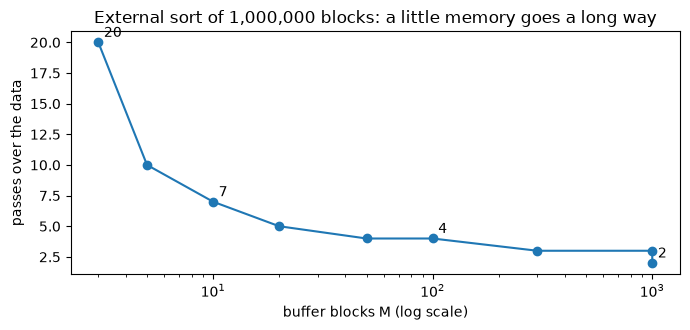

{3: 20, 5: 10, 10: 7, 20: 5, 50: 4, 100: 4, 300: 3, 1000: 3, 1001: 2}


In [6]:
# How the number of passes depends on M for a 1,000,000-block relation (formula only)
b_big = 1_000_000
Ms = [3, 5, 10, 20, 50, 100, 300, 1000, 1001]
passes = [1 + merge_passes(b_big, M) for M in Ms]
plt.figure(figsize=(7, 3.4))
plt.plot(Ms, passes, marker='o'); plt.xscale('log')
plt.xlabel('buffer blocks M (log scale)'); plt.ylabel('passes over the data')
plt.title('External sort of 1,000,000 blocks: a little memory goes a long way')
for M, p in zip(Ms, passes):
    if M in (3, 10, 100, 1001): plt.annotate(str(p), (M, p), textcoords='offset points', xytext=(4, 4))
plt.tight_layout(); plt.show()
print(dict(zip(Ms, passes)))

**What just happened?**
- For 108 blocks and M = 5 we got **22 → 6 → 2 → 1 runs, 4 passes, 864 I/Os**, exactly the worked example; every measured I/O count equals
  the formula, and every output equals Python's `sorted`.
- With M = 3 (only 2-way merges) the number of passes grows to log₂ of the number of runs; with M ≥ √b_r roughly, **two passes** suffice:
  sort 1,000,000 blocks (4 GB at 4 KB) with M = 1,001 buffers (4 MB) in 2 passes. This is why "two-pass algorithms" are the norm in databases.

Complexity: O(b_r log_{M−1}(b_r / M)) I/Os; CPU O(n log n).

> ⚠️ **Common mistake.** Using M-way instead of (M − 1)-way merging. One buffer must be reserved for the **output**.

---
## 5. Join algorithms

> **In plain English:** matching rows of two tables can be done in very different ways, and the clever ways are thousands of times cheaper on large tables.

We join `r ⋈_{r.key = s.key} s`, where **r is the outer** relation (the one we loop over) and **s the inner**. Formulas (Silberschatz, block transfers):

| Algorithm | Idea | Block transfers | Notes |
|---|---|---|---|
| **Nested-loop (NLJ)** | for each tuple of r, scan all of s | **n_r · b_s + b_r** (worst case) | works for any join condition |
| **Block nested-loop (BNLJ)** | for each **chunk of M − 2 blocks** of r, scan s once | **⌈b_r / (M−2)⌉ · b_s + b_r** | if r fits in memory: b_r + b_s |
| **Index nested-loop (INLJ)** | for each tuple of r, look it up in an index on s | **b_r + n_r · c** (c = cost of one index lookup) | needs an index on s's join attribute |
| **Sort-merge (SMJ)** | sort both on the key, then merge like a zipper | **b_r + b_s** + cost of sorting each | equi-joins; output is sorted |
| **Hash join (Grace)** | partition both with h₁ into M − 1 buckets, then build a hash table on each s-partition (h₂) and probe it with the r-partition | **3(b_r + b_s) + 4 n_h** | equi-joins; build input partitions must fit in memory (else recursive partitioning) |

Data: `r(r_id, key, payload)` with n tuples whose `key` is a **foreign key** into `s(key, name)` with n tuples, 10 tuples per block,
M = 50 buffer blocks. Every join must return exactly what `pandas.merge` returns.

In [7]:
BFR_J, M_J = 10, 50

def make_tables(n, seed=0):
    rg = np.random.default_rng(seed)
    s_keys = rg.permutation(10 * n)[:n]                                  # unique keys of s, random order
    s_rows = [(int(k), f'name{int(k)}') for k in s_keys]
    r_rows = [(i, int(k), int(p)) for i, (k, p) in enumerate(zip(rg.choice(s_keys, n), rg.integers(0, 1000, n)))]
    return Table('r', r_rows, BFR_J, ['r_id', 'key', 'payload']), Table('s', s_rows, BFR_J, ['key', 'name'])

def nested_loop_join(r, s, io):
    out = []
    for i in range(r.b):
        for tr in r.read(i, io):
            for j in range(s.b):                          # the WHOLE inner relation for EVERY outer tuple
                for ts in s.read(j, io):
                    if tr[1] == ts[0]:
                        out.append(tr + ts[1:])
    return out

def block_nested_loop_join(r, s, io, M=M_J):
    out = []
    for start in range(0, r.b, M - 2):                    # M-2 buffers for the outer, 1 for inner, 1 for output
        chunk = [t for i in range(start, min(start + M - 2, r.b)) for t in r.read(i, io)]
        for j in range(s.b):                              # scan the inner once per CHUNK
            for ts in s.read(j, io):
                for tr in chunk:
                    if tr[1] == ts[0]:
                        out.append(tr + ts[1:])
    return out

def build_index(s, fanout=50):
    """A model B+ tree on s.key: dict key -> (block, slot), with a height computed from the fan-out."""
    idx = {t[0]: (bi, si) for bi, blk in enumerate(s.blocks) for si, t in enumerate(blk)}
    height, reach = 1, fanout
    while reach < len(idx):                                   # smallest height with fanout**height >= number of keys
        height, reach = height + 1, reach * fanout
    return idx, height

def index_nested_loop_join(r, s, io, index):
    idx, height = index
    out = []
    for i in range(r.b):
        for tr in r.read(i, io):
            io.reads += height                            # descend the B+ tree: one block per level
            if tr[1] in idx:
                bi, si = idx[tr[1]]
                ts = s.read(bi, io)[si]                   # + one data block
                out.append(tr + ts[1:])
    return out

def sort_merge_join(r, s, io, M=M_J):
    r_sorted, _ = external_sort(r, key=lambda t: t[1], M=M, io=io)        # sort r on key (counts I/O)
    s_sorted, _ = external_sort(s, key=lambda t: t[0], M=M, io=io)        # sort s on key
    R = Table('r_sorted', r_sorted, r.bfr, r.cols); S = Table('s_sorted', s_sorted, s.bfr, s.cols)
    rs = [t for i in range(R.b) for t in R.read(i, io)]                     # merge phase: each block read once
    ss = [t for i in range(S.b) for t in S.read(i, io)]                     # (a real merge streams them block by block)
    out, i, j = [], 0, 0
    while i < len(rs) and j < len(ss):
        if rs[i][1] < ss[j][0]: i += 1
        elif rs[i][1] > ss[j][0]: j += 1
        else:                                                                 # equal keys: s.key is unique here,
            k = i                                                             # so pair every r with this s tuple
            while k < len(rs) and rs[k][1] == ss[j][0]:
                out.append(rs[k] + ss[j][1:]); k += 1
            i = k; j += 1
    return out

def grace_hash_join(r, s, io, M=M_J):
    n_h = M - 1                                                               # partitions (one output buffer each)
    h1 = lambda k: (k * 2654435761) % 2**32 % n_h
    def partition(table, col):
        parts, bufs = [[] for _ in range(n_h)], [[] for _ in range(n_h)]
        for i in range(table.b):
            for t in table.read(i, io):
                p = h1(t[col]); bufs[p].append(t)
                if len(bufs[p]) == table.bfr:                                 # buffer full: write a block
                    parts[p].append(bufs[p]); bufs[p] = []; io.writes += 1
        for p in range(n_h):
            if bufs[p]: parts[p].append(bufs[p]); io.writes += 1              # flush partially filled blocks
        return parts
    r_parts, s_parts = partition(r, 1), partition(s, 0)
    out = []
    for p in range(n_h):
        assert len(s_parts[p]) <= M - 2, 'build partition does not fit: would need recursive partitioning'
        build = {}
        for blk in s_parts[p]:                                                # build phase (the smaller input s)
            io.reads += 1
            for ts in blk: build.setdefault(ts[0], []).append(ts)
        for blk in r_parts[p]:                                                # probe phase
            io.reads += 1
            for tr in blk:
                for ts in build.get(tr[1], ()):
                    out.append(tr + ts[1:])
    return out

def pandas_join(r, s):
    R = pd.DataFrame(r.rows(), columns=r.cols); S = pd.DataFrame(s.rows(), columns=s.cols)
    return sorted(map(tuple, R.merge(S, on='key')[['r_id', 'key', 'payload', 'name']].itertuples(index=False, name=None)))

r, s = make_tables(2000)
index = build_index(s)
formulas = {
    'nested-loop':       r.n * s.b + r.b,
    'block nested-loop': math.ceil(r.b / (M_J - 2)) * s.b + r.b,
    'index nested-loop': r.b + r.n * (index[1] + 1),
    'sort-merge':        sort_cost_formula(r.b, M_J) + sort_cost_formula(s.b, M_J) + r.b + s.b,
    'hash join':         3 * (r.b + s.b) + 4 * (M_J - 1),
}
algos = {'nested-loop': nested_loop_join, 'block nested-loop': block_nested_loop_join,
         'index nested-loop': lambda r, s, io: index_nested_loop_join(r, s, io, index),
         'sort-merge': sort_merge_join, 'hash join': grace_hash_join}
truth = pandas_join(r, s)
rows = []
for name, fn in algos.items():
    io = IO(); t0 = time.perf_counter()
    res = fn(r, s, io)
    secs = time.perf_counter() - t0
    assert sorted(res) == truth, name                                         # identical to pandas.merge
    rows.append(dict(algorithm=name, measured_IO=io.total, formula_IO=formulas[name], python_seconds=round(secs, 3)))
cmp_df = pd.DataFrame(rows)
print(f'n_r = n_s = {r.n}, b_r = {r.b}, b_s = {s.b}, M = {M_J}, index height = {index[1]}, result rows = {len(truth)}')
print(cmp_df.to_string(index=False))
assert (cmp_df.measured_IO[:3] == cmp_df.formula_IO[:3]).all()                 # NLJ, BNLJ, INLJ match exactly
assert cmp_df.measured_IO[3] == cmp_df.formula_IO[3]                           # sort-merge matches
assert cmp_df.measured_IO[4] <= cmp_df.formula_IO[4]                           # hash join within the bound

n_r = n_s = 2000, b_r = 200, b_s = 200, M = 50, index height = 2, result rows = 2000
        algorithm  measured_IO  formula_IO  python_seconds
      nested-loop       400200      400200           2.813
block nested-loop         1200        1200           1.550
index nested-loop         6200        6200           0.013
       sort-merge         2000        2000           0.077
        hash join         1280        1396           0.022


**What just happened?** All five algorithms returned exactly the rows of `pandas.merge` (asserted). The I/O counts match the textbook formulas:
exactly for the loop joins and sort-merge, and within the 3(b_r + b_s) + 4 n_h bound for the hash join (the 4 n_h term covers partially filled
partition blocks). Note the scale: the naive nested-loop join needs **400,200** block transfers for two 200-block tables; the hash join needs about **1,300**.

### Benchmark on tables of increasing size
The quadratic algorithms (NLJ, BNLJ) are only *run* up to n = 2,000 tuples (their Python CPU time grows like n²); for larger n we plot their
formula (dashed).

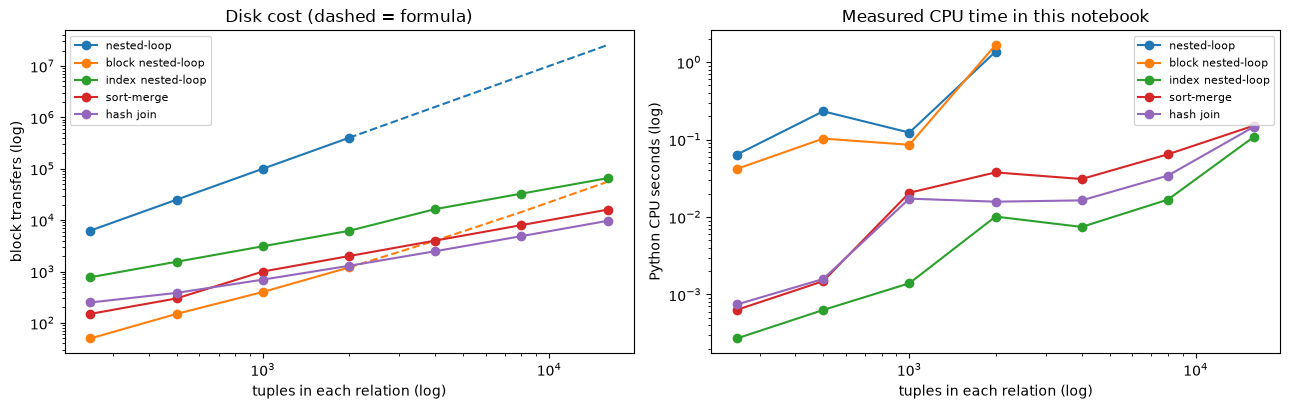

algorithm  block nested-loop  hash join  index nested-loop  nested-loop  sort-merge
n                                                                                  
250                       50        250                775         6275         150
500                      150        384               1550        25050         300
1000                     400        696               3100       100100        1000
2000                    1200       1292               6200       400200        2000
4000                    4000       2484              16400      1600400        4000
8000                   14400       4886              32800      6400800        8000
16000                  56000       9690              65600     25601600       16000


In [8]:
sizes = [250, 500, 1000, 2000, 4000, 8000, 16000]
bench = []
for n in sizes:
    r, s = make_tables(n, seed=n)
    index = build_index(s)
    truth = pandas_join(r, s)
    for name, fn in [('nested-loop', nested_loop_join), ('block nested-loop', block_nested_loop_join),
                     ('index nested-loop', lambda r, s, io: index_nested_loop_join(r, s, io, index)),
                     ('sort-merge', sort_merge_join), ('hash join', grace_hash_join)]:
        if name in ('nested-loop', 'block nested-loop') and n > 2000:
            est = r.n * s.b + r.b if name == 'nested-loop' else math.ceil(r.b / (M_J - 2)) * s.b + r.b
            bench.append(dict(n=n, algorithm=name, IO=est, seconds=np.nan, measured=False)); continue
        quadratic = name in ('nested-loop', 'block nested-loop')
        secs = math.inf
        for _ in range(1 if quadratic and n > 1000 else 3):           # best of 3 runs smooths out timing noise
            io = IO(); t0 = time.perf_counter(); res = fn(r, s, io); secs = min(secs, time.perf_counter() - t0)
        assert sorted(res) == truth, (name, n)
        bench.append(dict(n=n, algorithm=name, IO=io.total, seconds=secs, measured=True))
bench = pd.DataFrame(bench)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for name, g in bench.groupby('algorithm', sort=False):
    line, = axes[0].plot(g[g.measured].n, g[g.measured].IO, marker='o', label=name)
    if (~g.measured).any():
        axes[0].plot(g.n[g.n >= 2000], g.IO[g.n >= 2000], ls='--', color=line.get_color())
    axes[1].plot(g[g.measured].n, g[g.measured].seconds, marker='o', label=name)
for ax, yl, tt in [(axes[0], 'block transfers (log)', 'Disk cost (dashed = formula)'),
                   (axes[1], 'Python CPU seconds (log)', 'Measured CPU time in this notebook')]:
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('tuples in each relation (log)'); ax.set_ylabel(yl)
    ax.set_title(tt); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(bench.pivot(index='n', columns='algorithm', values='IO').astype(int).to_string())

**What just happened?**
- **Left plot (disk cost):** NLJ grows like n_r · b_s (quadratic: the line is twice as steep on the log-log plot). BNLJ is quadratic too, but divided by M − 2;
  while the outer relation fits in M − 2 blocks it costs just b_r + b_s. INLJ, sort-merge and hash join all grow roughly **linearly**. The hash join is the
  cheapest for large inputs; the INLJ pays one index descent per outer tuple, so it wins only when the outer relation is small or very selective.
- **Right plot (CPU in Python):** NLJ and BNLJ compare every pair, so their CPU time is quadratic even though BNLJ does far less I/O. Sort-merge pays
  for sorting; hashing is linear.

**Which join would an optimizer pick?**
- Small outer relation (after a selective filter) and an index on the inner join column → **index nested-loop**.
- Large equi-join, no useful order → **hash join** (needs memory ≈ √b_s blocks for two passes).
- Inputs already sorted (from an index or because the output must be sorted) → **sort-merge**.
- Non-equality join conditions (r.a < s.b, theta joins) → **block nested-loop** (or index nested-loop with a B+ tree on a range).

> 🎓 **Exam tip.** In NLJ/BNLJ, put the **smaller relation as the outer** (BNLJ) and remember the formulas use *n_r* (tuples) for NLJ but
> *b_r* (blocks) for BNLJ. A classic question: "n_r = 10,000, b_r = 400, n_s = 5,000, b_s = 100: NLJ cost?" r outer: 10,000·100 + 400 = 1,000,400;
> s outer: 5,000·400 + 100 = 2,000,100.

---
## 6. Projection, duplicate elimination and aggregation

> **In plain English:** removing duplicates and computing totals per group both need equal values brought together, by sorting or by hashing.

`SELECT DISTINCT dept FROM employee` and `GROUP BY` need tuples with equal values brought together. Two families, as for joins:

| | Sort-based | Hash-based |
|---|---|---|
| Duplicate elimination | external sort, then drop a tuple equal to its predecessor; duplicates can be removed **during** run generation and merging, so runs shrink | partition with h₁; in each partition keep an in-memory hash set |
| Aggregation (`GROUP BY g`: SUM, COUNT, MIN, MAX, AVG) | sort on g, then one pass computing each group's aggregate | hash table g → running (count, sum, min, max); AVG = sum/count at the end |
| Cost | like sorting (often cheaper: runs shrink) | like partitioning: about 3·b_r when it needs to spill, b_r if the groups fit in memory |

Running aggregates are what make this work in one pass: you never need all tuples of a group at once, only (count, sum, min, max).

In [9]:
def distinct_sort(rows):
    """Sort-based duplicate elimination."""
    out = []
    for t in sorted(rows):
        if not out or out[-1] != t:          # equal tuples are adjacent after sorting
            out.append(t)
    return out

def distinct_hash(rows, n_parts=8):
    """Hash-based: partition, then a hash set per partition."""
    parts = defaultdict(list)
    for t in rows: parts[hash(t) % n_parts].append(t)
    out = []
    for p in parts.values():
        out += list(dict.fromkeys(p))         # an order-preserving hash set
    return out

def groupby_hash(rows, gcol, vcol):
    """Hash aggregation with running aggregates."""
    acc = {}
    for t in rows:
        g, v = t[gcol], t[vcol]
        c, s_, mn, mx = acc.get(g, (0, 0, math.inf, -math.inf))
        acc[g] = (c + 1, s_ + v, min(mn, v), max(mx, v))
    return {g: (c, s_, mn, mx, s_ / c) for g, (c, s_, mn, mx) in acc.items()}

def groupby_sort(rows, gcol, vcol):
    """Sort-based aggregation: one pass over the sorted input."""
    out, cur = {}, None
    for t in sorted(rows, key=lambda t: t[gcol]):
        if t[gcol] != cur:
            cur = t[gcol]; out[cur] = [0, 0, math.inf, -math.inf]
        a = out[cur]; v = t[vcol]
        a[0] += 1; a[1] += v; a[2] = min(a[2], v); a[3] = max(a[3], v)
    return {g: (c, s_, mn, mx, s_ / c) for g, (c, s_, mn, mx) in out.items()}

proj = [(t[1],) for t in emp_rows]                                  # π_dept(employee) with duplicates
emp_df = pd.DataFrame(emp_rows, columns=['eid', 'dept', 'salary'])
expect = sorted(map(tuple, emp_df[['dept']].drop_duplicates().itertuples(index=False, name=None)))
assert distinct_sort(proj) == expect and sorted(distinct_hash(proj)) == expect
g_pd = emp_df.groupby('dept').salary.agg(['count', 'sum', 'min', 'max', 'mean'])
for impl in (groupby_hash, groupby_sort):
    got = impl(emp_rows, 1, 2)
    assert len(got) == len(g_pd)
    for g, row in g_pd.iterrows():
        assert got[g][:4] == (row['count'], row['sum'], row['min'], row['max']) and abs(got[g][4] - row['mean']) < 1e-9
print(f'{len(proj)} projected tuples -> {len(expect)} distinct departments (sort and hash agree with pandas)')
print('GROUP BY dept with COUNT/SUM/MIN/MAX/AVG: hash and sort aggregation agree with pandas; first groups:')
print(pd.DataFrame(groupby_hash(emp_rows, 1, 2), index=['count', 'sum', 'min', 'max', 'avg']).T.sort_index().head(3))

30000 projected tuples -> 300 distinct departments (sort and hash agree with pandas)
GROUP BY dept with COUNT/SUM/MIN/MAX/AVG: hash and sort aggregation agree with pandas; first groups:


   count         sum      min       max            avg
0   94.0   9819008.0  25091.0  199701.0  104457.531915
1   88.0   8636820.0  21704.0  196358.0   98145.681818
2  105.0  12275893.0  26186.0  194507.0  116913.266667


---
## 7. Materialization vs. pipelining

> **In plain English:** either finish each step completely and store its result, or pass rows along one by one like an assembly line.

An evaluation plan is a tree of operators. There are two ways to connect them:
- **Materialization**: evaluate the lowest operators first, write each **intermediate result to a temporary relation** (on disk if large), then
  feed it to the next operator. Simple, always possible, but costs extra writes and reads for every intermediate result.
- **Pipelining**: pass tuples from one operator to the next **as they are produced**, with no temporary relation.
  - **Demand-driven (pull, the iterator / "Volcano" model)**: each operator implements `open()`, `next()`, `close()`; the root calls `next()`
    and each operator pulls from its children only when needed. Used by most row-store DBMSs.
  - **Producer-driven (push)**: operators push tuples into buffers of their parents; used by many modern vectorized/compiled engines.
- **Blocking operators** cannot output anything until they have consumed their whole input: **sort**, the **build** side of a hash join,
  hash aggregation. They break the pipeline into stages.

Python generators are exactly demand-driven pipelines. We count how many tuples each strategy reads from the base table.

In [10]:
class Scan:
    def __init__(self, rows): self.rows, self.read = rows, 0
    def __iter__(self):
        for t in self.rows:
            self.read += 1                  # counts tuples pulled from the base table
            yield t

def Filter(child, pred):  return (t for t in child if pred(t))               # pipelined
def Proj(child, cols):    return (tuple(t[c] for c in cols) for t in child)  # pipelined
def Limit(child, k):      return itertools.islice(child, k)                  # pipelined, stops pulling after k
def Sort(child, key):     yield from sorted(child, key=key)                  # BLOCKING: must see every input tuple

def materialized(rows, pred, cols, k):
    """Each operator produces its full result before the next one starts."""
    stats = {'base tuples read': len(rows)}
    t1 = [t for t in rows if pred(t)];         stats['temp1 (after σ)'] = len(t1)
    t2 = [tuple(t[c] for c in cols) for t in t1]; stats['temp2 (after π)'] = len(t2)
    return t2[:k], stats

pred = lambda t: t[2] > 150_000                                         # salary > 150k
res_m, stats = materialized(emp_rows, pred, (0, 2), 5)
scan = Scan(emp_rows)
t0 = time.perf_counter()
res_p = list(Limit(Proj(Filter(scan, pred), (0, 2)), 5))
first_rows_ms = 1000 * (time.perf_counter() - t0)
assert res_m == res_p
print('query: SELECT eid, salary FROM employee WHERE salary > 150000 LIMIT 5')
print('materialized:', stats)
print(f'pipelined   : base tuples read = {scan.read} (and no temporary relations), {first_rows_ms:.3f} ms')

scan2 = Scan(emp_rows)
res_s = list(Limit(Sort(Filter(scan2, pred), key=lambda t: -t[2]), 5))   # ORDER BY salary DESC LIMIT 5
print(f'with ORDER BY (a blocking sort): base tuples read = {scan2.read}')
assert res_s == sorted([t for t in emp_rows if pred(t)], key=lambda t: -t[2])[:5]

query: SELECT eid, salary FROM employee WHERE salary > 150000 LIMIT 5
materialized: {'base tuples read': 30000, 'temp1 (after σ)': 8202, 'temp2 (after π)': 8202}
pipelined   : base tuples read = 12 (and no temporary relations), 3.331 ms
with ORDER BY (a blocking sort): base tuples read = 30000


**What just happened?** With materialization the plan read all 30,000 tuples and built two temporary relations before returning 5 rows.
The pipelined plan pulled tuples only until `LIMIT` had its 5 results (12 base tuples) and built nothing. Adding `ORDER BY` inserted a
**blocking** sort, so the pipeline had to consume the whole input again. (Optimizers rewrite `ORDER BY ... LIMIT k` into a **top-k heap**,
which is still blocking but needs only O(k) memory.)

Pipelining also needs the operator algorithms to be pipelinable: the probe side of a hash join and the outer side of an (index) nested-loop
join are; the build side of a hash join and external sort are not. **Double-pipelined (symmetric) hash join** keeps a hash table on *both*
inputs so it can produce results while both are still arriving (useful for streams).

---
## 8. Heuristic optimization

> **In plain English:** rewrite the query into an equivalent form that filters early and joins late, so every step handles fewer rows.

### Equivalence rules (Silberschatz)
Two expressions are **equivalent** if they produce the same set (multiset) of tuples on every legal database. The main rules:

| # | Rule | In words |
|---|---|---|
| 1 | σ_{θ1 ∧ θ2}(E) = σ_θ1(σ_θ2(E)) | a conjunctive selection is a cascade of selections |
| 2 | σ_θ1(σ_θ2(E)) = σ_θ2(σ_θ1(E)) | selections commute |
| 3 | π_L1(π_L2(... (E))) = π_L1(E) | only the outermost projection matters |
| 4 | σ_θ(E1 × E2) = E1 ⋈_θ E2 | a selection on a product is a theta join |
| 5 | E1 ⋈ E2 = E2 ⋈ E1 | joins are commutative |
| 6 | (E1 ⋈ E2) ⋈ E3 = E1 ⋈ (E2 ⋈ E3) | natural joins are associative |
| 7 | σ_θ0(E1 ⋈ E2) = σ_θ0(E1) ⋈ E2 if θ0 uses only E1's attributes | **push selections below joins** |
| 8 | π_L(E1 ⋈_θ E2) = π_L1(E1) ⋈_θ π_L2(E2), L1/L2 = attributes of L or θ from E1/E2 | **push projections below joins** |
| 9–11 | ∪ and ∩ are commutative and associative; σ distributes over ∪, ∩, − | set operations |

### The heuristics
1. Split conjunctive selections into a cascade (rule 1).
2. **Push selections down** as far as possible (rules 2, 7): reduces the size of everything above.
3. Combine selections with products into **joins** (rule 4): never compute a Cartesian product if a join condition exists.
4. Order joins so the most restrictive (smallest results) go first (rules 5, 6; done properly by cost-based search in section 9).
5. **Push projections down** (rules 3, 8): drop attributes nobody above needs.

We implement rules 1, 2, 4, 7 and 8 as tree rewrites and apply them to the canonical tree from section 1.

In [11]:
def schema(node):
    """Set of attributes produced by an expression."""
    if isinstance(node, Rel):     return set(SCHEMA[node.name])
    if isinstance(node, Project): return set(node.attrs)
    if isinstance(node, Select):  return schema(node.child)
    return schema(node.left) | schema(node.right)

def push_select(cond, node):
    """Place selection `cond` as deep as possible in `node` (rules 2, 4, 7)."""
    if isinstance(node, (Cross, Join)):
        L, R = schema(node.left), schema(node.right)
        if cond.attrs() <= L:
            node.left = push_select(cond, node.left); return node          # rule 7, left side
        if cond.attrs() <= R:
            node.right = push_select(cond, node.right); return node        # rule 7, right side
        if isinstance(node, Cross):
            return Join([cond], node.left, node.right)                      # rule 4: σ over × becomes ⋈
        node.conds.append(cond); return node                                # becomes part of the join condition
    if isinstance(node, Select):
        node.child = push_select(cond, node.child); return node             # rule 2: selections commute
    if isinstance(node, Rel):
        return Select([cond], node)
    raise ValueError('unexpected node')

def push_selections(tree):
    """Rule 1 (split the conjunction), then push each conjunct down."""
    assert isinstance(tree, Project) and isinstance(tree.child, Select)
    body = tree.child.child
    for cond in tree.child.conds:                                           # one conjunct at a time
        body = push_select(cond, body)
    return Project(tree.attrs, body)

def merge_selects(node):
    """Cosmetic: collapse σ_a(σ_b(E)) into σ_{a ∧ b}(E) (rule 1 backwards)."""
    if isinstance(node, Select) and isinstance(node.child, Select):
        return merge_selects(Select(node.conds + node.child.conds, node.child.child))
    for attr in ('child', 'left', 'right'):
        if hasattr(node, attr): setattr(node, attr, merge_selects(getattr(node, attr)))
    return node

def push_projections(node, needed):
    """Rule 8: keep only the attributes that the operators above need."""
    if isinstance(node, Project):
        return Project(node.attrs, push_projections(node.child, set(node.attrs)))
    if isinstance(node, Join):
        need = needed | {a for c in node.conds for a in c.attrs()}
        node.left = push_projections(node.left, need & schema(node.left))
        node.right = push_projections(node.right, need & schema(node.right))
        return node
    if isinstance(node, Select):
        inner = Select(node.conds, push_projections(node.child, needed | {a for c in node.conds for a in c.attrs()}))
        keep = [a for a in sorted(schema(node)) if a in needed]
        return Project(keep, inner) if set(keep) != schema(node) else inner
    if isinstance(node, Rel):
        keep = [a for a in SCHEMA[node.name] if a in needed]
        return Project(keep, node) if len(keep) < len(SCHEMA[node.name]) else node
    return node

import copy
step2 = merge_selects(push_selections(copy.deepcopy(canonical)))
step3 = push_projections(copy.deepcopy(step2), set(cols))
print('--- after pushing selections down and turning σ(×) into ⋈ ---'); show(step2)
print('\n--- after also pushing projections down ---'); show(step3)

--- after pushing selections down and turning σ(×) into ⋈ ---
π i_name, c_title
    ⋈ t_cid=c_id
        ⋈ i_id=t_iid
            σ i_dept='Music'
                instructor
            σ t_year=2017
                teaches
        course

--- after also pushing projections down ---
π i_name, c_title
    ⋈ t_cid=c_id
        ⋈ i_id=t_iid
            π i_id, i_name
                σ i_dept='Music'
                    π i_id, i_name, i_dept
                        instructor
            π t_cid, t_iid
                σ t_year=2017
                    teaches
        π c_id, c_title
            course


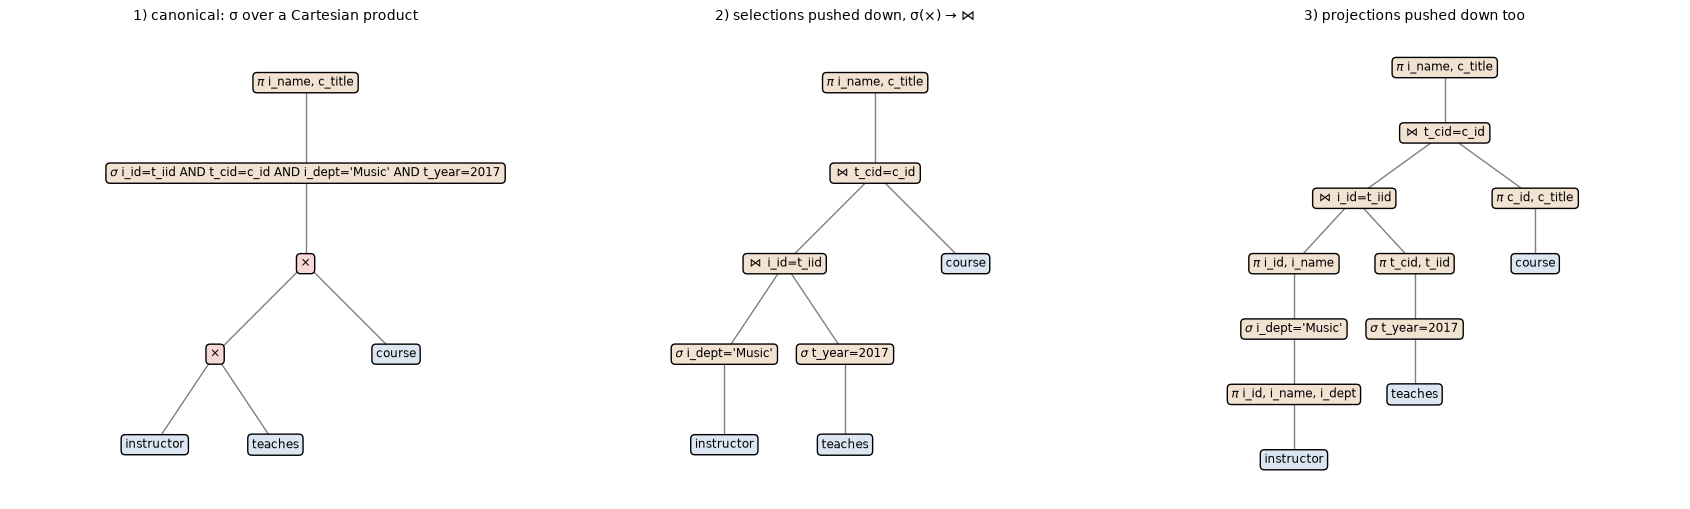

In [12]:
def label(node):
    if isinstance(node, Rel):     return node.name
    if isinstance(node, Project): return r'$\pi$ ' + ', '.join(node.attrs)
    if isinstance(node, Select):  return r'$\sigma$ ' + ' AND '.join(map(repr, node.conds))
    if isinstance(node, Cross):   return r'$\times$'
    return r'$\bowtie$ ' + ' AND '.join(map(repr, node.conds))

def children(node):
    if isinstance(node, (Project, Select)): return [node.child]
    if isinstance(node, (Cross, Join)):     return [node.left, node.right]
    return []

def draw_tree(root, ax, title):
    """Leaves get consecutive x positions; a parent sits above the middle of its children."""
    pos, counter = {}, [0]
    def place(n, depth):
        kids = children(n)
        if not kids:
            pos[id(n)] = (counter[0], -depth); counter[0] += 1
        else:
            for k in kids: place(k, depth + 1)
            xs = [pos[id(k)][0] for k in kids]
            pos[id(n)] = (sum(xs) / len(xs), -depth)
    place(root, 0)
    def draw(n):
        x, y = pos[id(n)]
        for k in children(n):
            kx, ky = pos[id(k)]; ax.plot([x, kx], [y, ky], color='gray', lw=1, zorder=1)
            draw(k)
        color = '#DCE6F2' if isinstance(n, Rel) else ('#F8D7D7' if isinstance(n, Cross) else '#F2E2D2')
        ax.text(x, y, label(n), ha='center', va='center', fontsize=8.5, zorder=2,
                bbox=dict(boxstyle='round,pad=0.35', fc=color, ec='black'))
    draw(root)
    xs = [p[0] for p in pos.values()]; ys = [p[1] for p in pos.values()]
    ax.set_xlim(min(xs) - 1.2, max(xs) + 1.2); ax.set_ylim(min(ys) - 0.6, 0.6)
    ax.set_title(title, fontsize=10); ax.axis('off')

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
draw_tree(canonical, axes[0], '1) canonical: σ over a Cartesian product')
draw_tree(step2, axes[1], '2) selections pushed down, σ(×) → ⋈')
draw_tree(step3, axes[2], '3) projections pushed down too')
plt.tight_layout(); plt.show()

Now we **evaluate** all three trees on generated data with a simple tree-walking evaluator and count the tuples each operator produces.

In [13]:
def make_university(n_instr=40, n_teaches=160, n_course=50, seed=3):
    rg = random.Random(seed)
    depts = ['Music', 'Physics', 'Comp. Sci.', 'History', 'Finance']
    db = {'instructor': [dict(i_id=i, i_name=f'instr{i}', i_dept=rg.choice(depts), salary=rg.randrange(40, 130) * 1000)
                         for i in range(n_instr)],
          'course':     [dict(c_id=c, c_title=f'course{c}', c_dept=rg.choice(depts), credits=rg.choice([3, 4]))
                         for c in range(n_course)],
          'teaches':    [dict(t_iid=rg.randrange(n_instr), t_cid=rg.randrange(n_course), t_year=rg.choice([2015, 2016, 2017, 2018]))
                         for _ in range(n_teaches)]}
    return db

def evaluate(node, db, counts):
    """Evaluate an RA tree bottom-up; counts[i] += tuples produced by each operator."""
    if isinstance(node, Rel):
        out = db[node.name]
    elif isinstance(node, Select):
        out = [t for t in evaluate(node.child, db, counts) if all(c.test(t) for c in node.conds)]
    elif isinstance(node, Project):
        out = [{a: t[a] for a in node.attrs} for t in evaluate(node.child, db, counts)]
    elif isinstance(node, Cross):
        L, R = evaluate(node.left, db, counts), evaluate(node.right, db, counts)
        out = [{**a, **b} for a in L for b in R]
    else:                                                       # Join: hash join on the equality conditions
        L, R = evaluate(node.left, db, counts), evaluate(node.right, db, counts)
        eq = [c for c in node.conds if c.op == '=' and c.right_is_attr]
        lk = [c.left if c.left in schema(node.left) else c.right for c in eq]
        rk = [c.right if c.left in schema(node.left) else c.left for c in eq]
        table = defaultdict(list)
        for b in R: table[tuple(b[k] for k in rk)].append(b)
        out = [{**a, **b} for a in L for b in table.get(tuple(a[k] for k in lk), [])
               if all(c.test({**a, **b}) for c in node.conds)]
    if not isinstance(node, Rel):
        counts.append((type(node).__name__, len(out)))         # count tuples produced by operators (not base tables)
    return out

db = make_university()
results, work = {}, {}
for name, tree in [('canonical', canonical), ('selections pushed', step2), ('selections + projections pushed', step3)]:
    counts = []
    t0 = time.perf_counter()
    res = evaluate(tree, db, counts)
    results[name] = sorted(tuple(sorted(t.items())) for t in res)
    work[name] = dict(result_rows=len(res), largest_intermediate=max(c for _, c in counts),
                      total_tuples_produced=sum(c for _, c in counts), seconds=round(time.perf_counter() - t0, 3))
assert results['canonical'] == results['selections pushed'] == results['selections + projections pushed']

con = sqlite3.connect(':memory:')                                 # and SQLite agrees
for tname, rows_ in db.items():
    cols_ = list(rows_[0]); con.execute(f'CREATE TABLE {tname}({", ".join(cols_)})')
    con.executemany(f'INSERT INTO {tname} VALUES ({",".join("?" * len(cols_))})', [tuple(r.values()) for r in rows_])
sql_res = sorted(tuple(sorted(dict(zip(cols, r)).items())) for r in con.execute(SQL))
assert sql_res == results['canonical']
work_df = pd.DataFrame(work).T
print(work_df.astype({'result_rows': int, 'largest_intermediate': int, 'total_tuples_produced': int}).to_string())

                                 result_rows  largest_intermediate  total_tuples_produced  seconds
canonical                                  4                320000                 326408    2.997
selections pushed                          4                    44                     60    0.004
selections + projections pushed            4                    50                    198    0.001


**What just happened?** All three trees (and SQLite) return the same rows: the rewrites are **equivalences**. But the canonical tree built a
Cartesian product of 40 × 160 × 50 = **320,000** tuples, while the optimized tree never produced more than a few dozen: the selections on
`i_dept` and `t_year` shrink the inputs before any join, and the joins replace the products. Pushing projections down does not reduce the
number of rows flowing between the operators (the extra π operators re-emit their input, so the total count above rises a little),
but every intermediate tuple becomes narrower: fewer bytes, more tuples per block, less memory.

> ⚠️ **Common mistake.** Pushing a selection that refers to attributes of **both** join inputs below the join. That is not allowed (rule 7 requires
> θ0 to use only one input's attributes); such a condition becomes part of the join condition instead, as `push_select` does.

---
## 9. Cost-based optimization

> **In plain English:** guess how many rows each step will produce using statistics, then pick the plan with the smallest estimated cost.

Heuristics say "push selections down"; they cannot say whether **index nested-loop or hash join** is cheaper, or which of the many join orders is
best. A cost-based optimizer **enumerates** alternative plans, **estimates** each one's cost from **statistics**, and picks the cheapest.

### 9.1 Catalog statistics (Silberschatz notation)
| Statistic | Meaning |
|---|---|
| n_r | number of tuples in r |
| b_r | number of blocks of r |
| l_r | size of a tuple of r in bytes |
| f_r | blocking factor (tuples per block) |
| V(A, r) | number of **distinct values** of attribute A in r |
| histograms | the distribution of values of A (section 9.3) |

### 9.2 Selectivity estimation
The **selectivity** of a predicate is the fraction of tuples that satisfy it. Classic estimates (assuming **uniform** values and **independent** attributes):

| Predicate | Estimated selectivity |
|---|---|
| A = v | 1 / V(A, r) |
| A ≤ v | (v − min(A)) / (max(A) − min(A)) |
| θ1 ∧ θ2 ∧ ... | s1 · s2 · ... (independence) |
| θ1 ∨ θ2 | 1 − (1 − s1)(1 − s2) |
| ¬θ | 1 − s |
| r ⋈_{r.A = s.A} s | size ≈ n_r · n_s / max(V(A, r), V(A, s)); if A is a key of s and a foreign key in r: exactly n_r |

In [14]:
rng = np.random.default_rng(7)
n_people = 100_000
people = pd.DataFrame({
    'age':    rng.integers(18, 80, n_people),                                    # roughly uniform
    'income': np.round(rng.lognormal(mean=10.5, sigma=0.7, size=n_people)),      # heavily skewed
    'city':   rng.choice(50, n_people),
})
people['senior'] = people.age >= 60                                              # perfectly correlated with age!
stats = {c: dict(min=people[c].min(), max=people[c].max(), V=people[c].nunique()) for c in ['age', 'income', 'city']}

def est_eq(col):        return 1 / stats[col]['V']
def est_le(col, v):     return min(max((v - stats[col]['min']) / (stats[col]['max'] - stats[col]['min']), 0), 1)

cases = [
    ('city = 7',                         est_eq('city'),                         (people.city == 7).mean()),
    ('age <= 30',                        est_le('age', 30),                      (people.age <= 30).mean()),
    ('income <= 30,000 (skewed column)', est_le('income', 30_000),               (people.income <= 30_000).mean()),
    ('city = 7 AND age <= 30',           est_eq('city') * est_le('age', 30),     ((people.city == 7) & (people.age <= 30)).mean()),
    ('city = 7 OR age <= 30',            1 - (1 - est_eq('city')) * (1 - est_le('age', 30)),
                                                                                 ((people.city == 7) | (people.age <= 30)).mean()),
    ('age >= 60 AND senior (correlated)', (1 - est_le('age', 59)) * 0.5,          ((people.age >= 60) & people.senior).mean()),
]
sel = pd.DataFrame(cases, columns=['predicate', 'estimated', 'actual'])
sel['estimated rows'] = (sel.estimated * n_people).round().astype(int)
sel['actual rows'] = (sel.actual * n_people).round().astype(int)
sel['error factor'] = (np.maximum(sel.estimated, sel.actual) / np.minimum(sel.estimated, sel.actual)).round(2)
print(sel.round(4).to_string(index=False))

                        predicate  estimated  actual  estimated rows  actual rows  error factor
                         city = 7     0.0200  0.0207            2000         2073          1.04
                        age <= 30     0.1967  0.2090           19672        20904          1.06
 income <= 30,000 (skewed column)     0.0324  0.3919            3244        39193         12.08
           city = 7 AND age <= 30     0.0039  0.0043             393          430          1.09
            city = 7 OR age <= 30     0.2128  0.2255           21279        22547          1.06
age >= 60 AND senior (correlated)     0.1639  0.3246           16393        32464          1.98


**What just happened?** On uniform, independent columns (`city`, `age`) the textbook formulas are within a few percent. Two classic failures:
- **Skew**: incomes follow a long-tailed distribution, so "uniform between min and max" badly underestimates how many people earn ≤ 30,000
  (most of the mass is at the low end).
- **Correlation**: `senior` is true exactly when `age >= 60`, but independence multiplies the two selectivities (we assumed a 50% selectivity for
  the boolean `senior`) and underestimates by about 2x. Errors like these multiply through a plan with many joins, and are the main reason optimizers
  pick bad plans. Fixes: **histograms** for skew, multi-column statistics (`CREATE STATISTICS` in PostgreSQL) for correlation.

### 9.3 Histograms
- **Equi-width**: split [min, max] into k equal-width buckets and store the count in each.
- **Equi-depth (equi-height)**: choose bucket boundaries so that every bucket holds the **same number of tuples** (n / k); store the boundaries.
  Better for skewed data: narrow buckets where the data is dense.
Within a bucket we still assume uniformity. Let us estimate 300 random range predicates `lo ≤ income ≤ hi` with each method.

                        mean abs error (% of table)  95th percentile (% of table)
uniform (min/max only)                        31.15                         70.78
equi-width histogram                           4.93                         11.95
equi-depth histogram                           0.40                          1.84


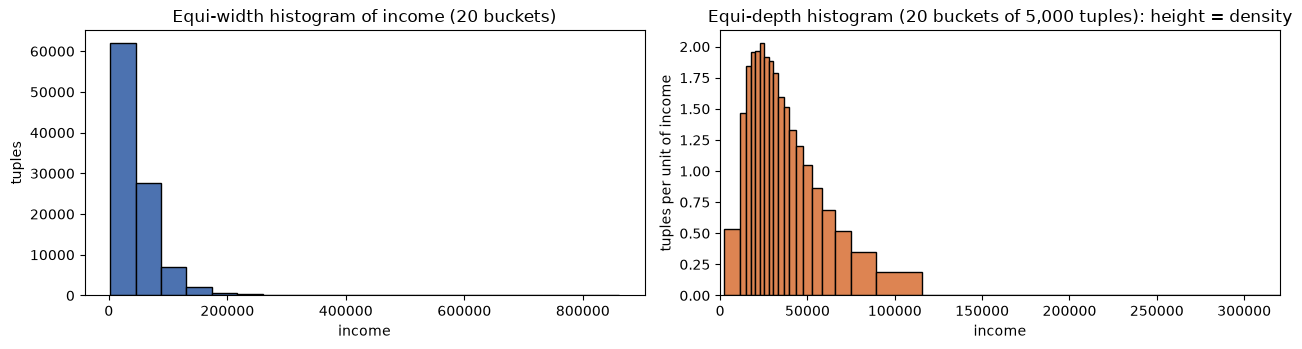

In [15]:
K = 20
inc = np.sort(people.income.to_numpy())
ew_edges = np.linspace(inc[0], inc[-1], K + 1)                    # equi-width boundaries
ew_counts = np.histogram(inc, bins=ew_edges)[0]
ed_edges = np.quantile(inc, np.linspace(0, 1, K + 1))             # equi-depth boundaries (quantiles)
ed_counts = np.histogram(inc, bins=ed_edges)[0]

def hist_estimate(edges, counts, lo, hi):
    """Rows with lo <= x <= hi, assuming values are uniform inside each bucket."""
    total = 0.0
    for a, b, c in zip(edges[:-1], edges[1:], counts):
        overlap = max(0.0, min(hi, b) - max(lo, a))
        total += c * (overlap / (b - a) if b > a else float(lo <= a <= hi))
    return total

assert abs(hist_estimate(ew_edges, ew_counts, inc[0], inc[-1]) - n_people) < 1e-6   # whole range = all rows
assert abs(hist_estimate(ed_edges, ed_counts, inc[0], inc[-1]) - n_people) < 1e-6

rg = np.random.default_rng(11)
errs = {'uniform (min/max only)': [], 'equi-width histogram': [], 'equi-depth histogram': []}
for _ in range(300):
    lo, hi = np.sort(rg.choice(inc, 2))                           # realistic ranges: endpoints drawn from the data
    actual = np.searchsorted(inc, hi, 'right') - np.searchsorted(inc, lo, 'left')
    ests = {'uniform (min/max only)': n_people * (hi - lo) / (inc[-1] - inc[0]),
            'equi-width histogram': hist_estimate(ew_edges, ew_counts, lo, hi),
            'equi-depth histogram': hist_estimate(ed_edges, ed_counts, lo, hi)}
    for k, e in ests.items():
        errs[k].append(abs(e - actual) / n_people)                # error as a fraction of the table
err_df = pd.DataFrame({k: [np.mean(v) * 100, np.percentile(v, 95) * 100] for k, v in errs.items()},
                      index=['mean abs error (% of table)', '95th percentile (% of table)']).T
print(err_df.round(2))
assert err_df.iloc[2, 0] < err_df.iloc[1, 0] < err_df.iloc[0, 0]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].bar(ew_edges[:-1], ew_counts, width=np.diff(ew_edges), align='edge', edgecolor='black', color='#4C72B0')
axes[0].set_title(f'Equi-width histogram of income ({K} buckets)'); axes[0].set_xlabel('income'); axes[0].set_ylabel('tuples')
axes[1].bar(ed_edges[:-1], ed_counts / np.diff(ed_edges), width=np.diff(ed_edges), align='edge', edgecolor='black', color='#DD8452')
axes[1].set_title(f'Equi-depth histogram ({K} buckets of {n_people // K:,} tuples): height = density')
axes[1].set_xlabel('income'); axes[1].set_ylabel('tuples per unit of income')
axes[1].set_xlim(0, np.quantile(inc, 0.999))
plt.tight_layout(); plt.show()

**What just happened?** With only min/max, range estimates on the skewed income column are off by a large fraction of the table. An equi-width
histogram helps, but most of its buckets are nearly empty (the right tail) while one or two buckets hold most tuples. The equi-depth histogram
puts narrow buckets where the data is dense and gives the smallest errors (asserted: equi-depth < equi-width < uniform).
PostgreSQL stores an equi-depth histogram plus a list of **most common values** per column; SQL Server and Oracle use similar structures.

### 9.4 Join ordering with dynamic programming (System R)
For n relations there are n! left-deep join orders and (2(n−1))!/(n−1)! join trees in total (bushy included): for n = 10 that is
3.6 million left-deep orders and 17.6 billion trees. **System R** (Selinger et al., 1979) observed that the best plan for a set of relations
S can be built from the best plan for a subset: **dynamic programming over subsets**:

  best[{R}] = scan of R
  best[S] = min over R ∈ S of  cost(best[S − {R}]) + cost of joining (S − {R}) with R      (left-deep)

This needs O(2ⁿ) subsets instead of n! orders. System R considered only **left-deep** trees (the inner input is always a base relation,
so it can use an index) and avoided Cartesian products when possible. It also kept the best plan per **interesting order** (a plan producing
sorted output can make a later merge join or `ORDER BY` free).

**Toy cost model** (a standard one for teaching, "C_out"): the cost of a plan is the **sum of the sizes of its intermediate results**; sizes come
from the join-size formula of 9.2. Our query: customers from one country, their orders, the line items, and only products in one category.

In [16]:
# Statistics of four relations (after their local selections), as an optimizer would read them from the catalog
REL = {
    'C': dict(n=2_000 // 20, desc='customer WHERE country = PK (1/20 of 2,000)'),
    'O': dict(n=20_000,      desc='orders'),
    'L': dict(n=60_000,      desc='lineitem'),
    'P': dict(n=500 // 10,   desc='product WHERE category = books (1/10 of 500)'),
}
# join predicates: (rel1, rel2, V(A, rel1), V(A, rel2))  -- distinct join-attribute values in each relation
PRED = [('C', 'O', 2_000, 2_000),      # C.cid = O.cid   (V(cid, C) taken before the selection, as a catalog would)
        ('O', 'L', 20_000, 20_000),    # O.oid = L.oid
        ('L', 'P', 500, 500)]          # L.pid = P.pid

def est_size(S):
    """Estimated size of joining the set S: product of sizes times the selectivity 1/max(V,V) of each predicate inside S."""
    size = math.prod(REL[x]['n'] for x in S)
    for a, b, va, vb in PRED:
        if a in S and b in S:
            size /= max(va, vb)
    return size

def connected(S, x):
    return any((a == x and b in S) or (b == x and a in S) for a, b, _, _ in PRED)

def dp_left_deep(rels, allow_cross=False):
    best = {frozenset([x]): (0.0, [x]) for x in rels}                 # cost, order
    table = []
    for k in range(2, len(rels) + 1):
        for S in map(frozenset, itertools.combinations(rels, k)):
            cands = []
            for x in S:
                rest = S - {x}
                if rest in best and (allow_cross or connected(rest, x)):
                    c, order = best[rest]
                    cands.append((c + est_size(S), order + [x]))       # add the size of this new intermediate result
            if cands:
                best[S] = min(cands)
                table.append(dict(subset='{' + ','.join(sorted(S)) + '}', est_size=round(est_size(S)),
                                  best_order=' ⋈ '.join(best[S][1]), cost=round(best[S][0])))
    return best[frozenset(rels)], pd.DataFrame(table)

def brute_force(rels, allow_cross=False):
    plans = []
    for perm in itertools.permutations(rels):
        cost, ok = 0.0, True
        for i in range(2, len(perm) + 1):
            if not allow_cross and not connected(set(perm[:i - 1]), perm[i - 1]):
                ok = False; break
            cost += est_size(set(perm[:i]))
        if ok: plans.append((cost, list(perm)))
    return sorted(plans)

(best_cost, best_order), dp_table = dp_left_deep(list(REL))
plans = brute_force(list(REL))
assert abs(plans[0][0] - best_cost) < 1e-6                             # DP finds the same optimum as trying every order
print(dp_table.to_string(index=False))
print(f'\nDP best left-deep order: {" ⋈ ".join(best_order)}  (cost {best_cost:,.0f})')
print(f'{len(plans)} cross-product-free left-deep orders exist; worst: {" ⋈ ".join(plans[-1][1])} (cost {plans[-1][0]:,.0f})')
all_plans = brute_force(list(REL), allow_cross=True)
print(f'allowing Cartesian products: {len(all_plans)} orders, worst {" ⋈ ".join(all_plans[-1][1])} (cost {all_plans[-1][0]:,.0f})')

   subset  est_size    best_order  cost
    {C,O}      1000         C ⋈ O  1000
    {L,O}     60000         L ⋈ O 60000
    {L,P}      6000         L ⋈ P  6000
  {C,L,O}      3000     C ⋈ O ⋈ L  4000
  {L,O,P}      6000     L ⋈ P ⋈ O 12000
{C,L,O,P}       300 C ⋈ O ⋈ L ⋈ P  4300

DP best left-deep order: C ⋈ O ⋈ L ⋈ P  (cost 4,300)
8 cross-product-free left-deep orders exist; worst: O ⋈ L ⋈ P ⋈ C (cost 66,300)
allowing Cartesian products: 24 orders, worst L ⋈ C ⋈ P ⋈ O (cost 6,600,300)


Are the estimates any good? We build actual tables with these statistics and run the best and the worst orders with pandas, measuring the real
intermediate result sizes.

In [17]:
rg = np.random.default_rng(5)
customer = pd.DataFrame({'cid': np.arange(2000), 'country': rg.choice(20, 2000)})
orders_t = pd.DataFrame({'oid': np.arange(20_000), 'cid': rg.integers(0, 2000, 20_000)})
lineitem = pd.DataFrame({'oid': rg.integers(0, 20_000, 60_000), 'pid': rg.integers(0, 500, 60_000)})
product  = pd.DataFrame({'pid': np.arange(500), 'category': rg.choice(10, 500)})
tables = {'C': customer[customer.country == 0][['cid']], 'O': orders_t, 'L': lineitem, 'P': product[product.category == 0][['pid']]}

def run_order(order):
    """Execute a left-deep order with pandas merges; return the actual sizes of the intermediate results."""
    cur, have, sizes = tables[order[0]], {order[0]}, []
    for x in order[1:]:
        on = [c for c in cur.columns if c in tables[x].columns]      # the shared join attribute
        cur = cur.merge(tables[x], on=on); have.add(x)
        sizes.append(len(cur))
    return cur, sizes

res_best, sizes_best = run_order(best_order)
res_worst, sizes_worst = run_order(plans[-1][1])
canon = lambda d: d[['cid', 'oid', 'pid']].sort_values(['cid', 'oid', 'pid']).reset_index(drop=True)
assert canon(res_best).equals(canon(res_worst))                           # same answer either way
est_best = [round(est_size(set(best_order[:i]))) for i in range(2, 5)]
est_worst = [round(est_size(set(plans[-1][1][:i]))) for i in range(2, 5)]
print('best order ', best_order, '| estimated sizes', est_best, '| actual sizes', sizes_best, '| actual cost', sum(sizes_best))
print('worst order', plans[-1][1], '| estimated sizes', est_worst, '| actual sizes', sizes_worst, '| actual cost', sum(sizes_worst))
print(f'the DP choice does {sum(sizes_worst) / sum(sizes_best):.0f}x less intermediate work than the worst connected order')
print('number of left-deep orders n! and of all join trees (2(n-1))!/(n-1)!:',
      {n: (math.factorial(n), math.factorial(2 * (n - 1)) // math.factorial(n - 1)) for n in [3, 4, 6, 10]})

best order  ['C', 'O', 'L', 'P'] | estimated sizes [1000, 3000, 300] | actual sizes [1221, 3693, 362] | actual cost 5276
worst order ['O', 'L', 'P', 'C'] | estimated sizes [60000, 6000, 300] | actual sizes [60000, 5765, 362] | actual cost 66127
the DP choice does 13x less intermediate work than the worst connected order
number of left-deep orders n! and of all join trees (2(n-1))!/(n-1)!: {3: (6, 12), 4: (24, 120), 6: (720, 30240), 10: (3628800, 17643225600)}


**What just happened?**
- The DP table grows plans subset by subset; for every subset it keeps only the cheapest way to build it. Its answer equals the brute-force
  optimum over every cross-product-free left-deep order (asserted).
- The chosen plan starts from the **small, filtered** relations (customers in one country, books) and joins them in early, keeping every
  intermediate result small. The worst connected order starts with the big orders ⋈ lineitem join and pays for a 60,000-row intermediate result.
- The estimated sizes are close to the actual ones because our keys are uniform and independent; the real data confirmed a large gap between
  the best and worst orders, and both orders produce identical results.

Real optimizers add: several join algorithms per step (cost formulas of section 5 instead of C_out), interesting orders, bushy trees, and for
many relations (> 10 to 15) they switch to heuristics or randomized search (PostgreSQL's genetic optimizer, `geqo`).

---
## 10. Real plans in SQLite and rewriting a slow query

> **In plain English:** we read the plans a real database chooses and turn a query that takes over a second into one that takes milliseconds.

`EXPLAIN QUERY PLAN` prints one line per step: `SCAN t` (full scan), `SEARCH t USING INDEX ...` (index lookup), `USE TEMP B-TREE FOR ...`
(a sort or a temporary distinct/group structure), `CORRELATED SCALAR SUBQUERY` (re-executed for every outer row), `AUTOMATIC INDEX` (SQLite built a
temporary index because it estimated that would be cheaper), `BLOOM FILTER` (a probabilistic pre-filter for joins). Indentation shows nesting; the
**first table listed in a join is the outer loop** (SQLite implements joins as nested loops, using indexes and automatic indexes for the inner side).

In [18]:
con = sqlite3.connect(':memory:')
rg = np.random.default_rng(42)
N_CUST, N_ORD = 300, 20_000
con.execute('CREATE TABLE customers(id INTEGER PRIMARY KEY, name TEXT, country TEXT)')
con.execute('CREATE TABLE orders(id INTEGER PRIMARY KEY, customer_id INT, amount REAL, created TEXT)')
con.executemany('INSERT INTO customers VALUES (?,?,?)',
                [(i, f'cust{i}', ['PK', 'US', 'DE', 'IN', 'BR'][i % 5]) for i in range(1, N_CUST + 1)])
created = (pd.Timestamp('2023-01-01') + pd.to_timedelta(rg.integers(0, 3 * 365 * 86400, N_ORD), unit='s')).astype(str).tolist()
con.executemany('INSERT INTO orders(customer_id, amount, created) VALUES (?,?,?)',
                zip(rg.integers(1, N_CUST + 1, N_ORD).tolist(), rg.gamma(2.0, 40.0, N_ORD).round(2).tolist(), created))
con.commit()

def plan(sql):
    """Indented EXPLAIN QUERY PLAN output."""
    rows = list(con.execute('EXPLAIN QUERY PLAN ' + sql))
    depth = {0: 0}
    out = []
    for node_id, parent, _, detail in rows:
        depth[node_id] = depth.get(parent, 0) + 1
        out.append('  ' * (depth[node_id] - 1) + detail)
    return '\n'.join(out)

def timed(sql, repeat=3):
    best = math.inf
    for _ in range(repeat):
        t0 = time.perf_counter(); res = con.execute(sql).fetchall(); best = min(best, time.perf_counter() - t0)
    return res, 1000 * best

join_sql = """SELECT c.country, COUNT(*), ROUND(SUM(o.amount), 2) FROM customers c JOIN orders o ON o.customer_id = c.id
WHERE c.country = 'PK' GROUP BY c.country"""
print('join, no index on orders.customer_id:\n' + plan(join_sql), '\n')
con.execute('CREATE INDEX idx_orders_customer ON orders(customer_id)')
con.execute('ANALYZE')                                         # collect statistics (sqlite_stat1) for the optimizer
print('join, with the index and statistics:\n' + plan(join_sql))
print('\nstatistics SQLite collected:', con.execute('SELECT * FROM sqlite_stat1').fetchall())
con.execute('DROP INDEX idx_orders_customer'); con.execute('ANALYZE');      # back to "no index" for the next experiment

join, no index on orders.customer_id:
SCAN o
SEARCH c USING INTEGER PRIMARY KEY (rowid=?)
USE TEMP B-TREE FOR GROUP BY 

join, with the index and statistics:
SCAN c
SEARCH o USING INDEX idx_orders_customer (customer_id=?)

statistics SQLite collected: [('orders', 'idx_orders_customer', '20000 67'), ('customers', None, '300')]


Read the two plans: without an index on `orders.customer_id`, SQLite makes `orders` the outer loop and looks each customer up by its primary key
(the rowid). With the index (and `ANALYZE` statistics), it flips the join order: it scans the small `customers` table, keeps the 'PK'
customers, and uses the index to fetch only their orders. The `sqlite_stat1` rows are the catalog statistics: table size and the average number of rows per
distinct index key, i.e. n_r and n_r / V(A, r).

### Rewriting a slow query
"Customers whose total spending is above 3,000" written with a **correlated subquery** and no index:

In [19]:
slow_sql = """SELECT c.id FROM customers c
WHERE (SELECT SUM(o.amount) FROM orders o WHERE o.customer_id = c.id) > 3000"""
print(plan(slow_sql))
slow_res, slow_ms = timed(slow_sql, repeat=1)

rewrite_sql = """WITH spend AS (SELECT customer_id, SUM(amount) AS total FROM orders GROUP BY customer_id)
SELECT c.id FROM customers c JOIN spend s ON s.customer_id = c.id WHERE s.total > 3000"""
print('\n' + plan(rewrite_sql))
fast_res, fast_ms = timed(rewrite_sql)

con.execute('CREATE INDEX idx_orders_customer ON orders(customer_id, amount)')   # alternative fix: a covering index
print('\n' + plan(slow_sql))
idx_res, idx_ms = timed(slow_sql)
assert sorted(slow_res) == sorted(fast_res) == sorted(idx_res)
print(f'\n{len(slow_res)} customers in every version')
print(pd.Series({'correlated subquery, no index': slow_ms, 'rewritten as GROUP BY + join': fast_ms,
                 'correlated subquery + covering index': idx_ms}).round(2).rename('ms').to_string())

SCAN c
CORRELATED SCALAR SUBQUERY 1
  SCAN o



CO-ROUTINE spend
  SCAN orders
  USE TEMP B-TREE FOR GROUP BY
SCAN s
SEARCH c USING INTEGER PRIMARY KEY (rowid=?)

SCAN c
CORRELATED SCALAR SUBQUERY 1
  SEARCH o USING COVERING INDEX idx_orders_customer (customer_id=?)



300 customers in every version
correlated subquery, no index           2332.40
rewritten as GROUP BY + join              18.40
correlated subquery + covering index       8.63


**What just happened?** The correlated subquery is re-executed **once per customer**, and each execution scans all 20,000 orders
(300 × 20,000 = 6 million row visits). Two standard fixes, both returning the same customers:
1. **Decorrelate**: compute every customer's total in **one** pass with `GROUP BY` and join (many optimizers do this rewrite automatically; SQLite does not).
2. **Index** the correlation column so each re-execution is an index range lookup; making it **covering** `(customer_id, amount)` avoids table lookups.

More rewrites worth knowing:
- Make predicates **sargable**: `WHERE created >= '2025-01-01' AND created < '2026-01-01'` instead of `WHERE strftime('%Y', created) = '2025'`.
- Replace `OR` across different columns with `UNION` so each branch can use its own index.
- `EXISTS` instead of `IN (subquery)` or `COUNT(*) > 0` when you only need to know whether a match exists.
- Select only the columns you need (enables covering indexes; less data through every pipeline).

In [20]:
con.execute('CREATE INDEX idx_orders_created ON orders(created)')
q_fn  = "SELECT COUNT(*), ROUND(SUM(amount), 2) FROM orders WHERE strftime('%Y', created) = '2025'"
q_rng = "SELECT COUNT(*), ROUND(SUM(amount), 2) FROM orders WHERE created >= '2025-01-01' AND created < '2026-01-01'"
r1, t1 = timed(q_fn); r2, t2 = timed(q_rng)
assert r1 == r2
print('non-sargable:', plan(q_fn), f'-> {t1:.2f} ms')
print('sargable    :', plan(q_rng), f'-> {t2:.2f} ms')
con.close()

non-sargable: SCAN orders -> 37.78 ms
sargable    : SEARCH orders USING INDEX idx_orders_created (created>? AND created<?) -> 13.27 ms


**What just happened?** Both queries count the same orders, but only the range form can use `idx_orders_created`: SQLite cannot search an index for
the *output* of `strftime`. (On this small, in-memory table the full scan is still quick, so the gap is modest; it grows with the table size and with the
selectivity of the range.)

For a bigger, end-to-end example of these ideas (CTEs, indexes before and after, `EXPLAIN QUERY PLAN` on a realistic schema) continue with
[`../01_sql/02_industry_sql_for_ml_feature_extraction.ipynb`](../01_sql/02_industry_sql_for_ml_feature_extraction.ipynb).

---
## 11. 🔗 How this connects to modern AI

> **In plain English:** the same optimizer tricks run inside Spark, DuckDB and Polars, and decide how fast your feature pipelines are.

- **Feature extraction is query processing.** Building training sets means big joins and aggregations; knowing that a hash join is linear while a
  nested-loop join is quadratic, and that filtering before joining (selection push-down) shrinks every step, is what makes feature pipelines fast.
  See [`../01_sql/02_industry_sql_for_ml_feature_extraction.ipynb`](../01_sql/02_industry_sql_for_ml_feature_extraction.ipynb) and
  [`../06_data_engineering/01_data_engineering.ipynb`](../06_data_engineering/01_data_engineering.ipynb).
- **Dataframe engines are query optimizers.** Spark SQL (Catalyst), DuckDB and Polars' lazy API build a logical plan and apply exactly these rules:
  predicate push-down and projection push-down (often all the way into Parquet files, skipping row groups by their min/max statistics),
  join reordering and hash joins. Writing `df.filter(...)` before `df.join(...)` in eager pandas is doing the optimizer's job by hand.
- **Learned query optimization.** Cardinality estimation is a regression problem: learned estimators and learned optimizers (Neo, Bao and their
  successors) use ML models to fix exactly the skew and correlation errors of section 9.2.
- **Text-to-SQL with LLMs.** An LLM that writes SQL can produce correct but slow queries (correlated subqueries, non-sargable filters). Tools that feed
  `EXPLAIN` output back to the model, or that apply rewrite rules, are the practical fix. See
  [`../05_db_in_ai/01_databases_in_ai.ipynb`](../05_db_in_ai/01_databases_in_ai.ipynb).
- **Vector search query planning.** Vector databases must decide whether to filter metadata **before** the ANN search (pre-filtering) or
  **after** it (post-filtering): a selectivity-based choice, just like index scan vs. full scan.

---
## 12. Recap

> **In plain English:** the whole notebook on one page.

- Pipeline: **parse** (syntax + names) → **translate** to relational algebra → **optimize** → **evaluation plan** → **execute**.
- Cost = block transfers (and seeks); notation n_r, b_r, M.
- **Selection**: linear scan b_r (b_r/2 for a key), clustering index h_i + matching blocks, secondary index h_i + matching records.
- **External merge sort**: runs of M blocks, then (M−1)-way merges; 2·b_r·(1 + ⌈log_{M−1}⌈b_r/M⌉⌉) I/Os; two passes when M ≳ √b_r.
- **Joins**: NLJ n_r·b_s + b_r; BNLJ ⌈b_r/(M−2)⌉·b_s + b_r; INLJ b_r + n_r·c; sort-merge b_r + b_s + sorting; hash 3(b_r + b_s) + 4n_h.
- Duplicate elimination and aggregation by **sorting or hashing**, with running aggregates.
- **Pipelining** (iterator model) avoids temporary relations; **blocking** operators (sort, hash build) break pipelines.
- **Heuristics**: split conjunctions, push σ down, turn σ(×) into ⋈, push π down.
- **Cost-based**: statistics (n_r, V(A,r), histograms) → selectivity estimates (uniformity, independence: both can fail) → **DP over subsets** for join order.
- Read real plans with `EXPLAIN QUERY PLAN`; fix slow queries by decorrelating, indexing, and writing sargable predicates.

## Practice problems

**1. (Easy)** List the four stages of query processing and say which one uses catalog statistics.

<details><summary>Show solution</summary>

Parsing (with name resolution), translation to relational algebra, optimization, execution of the evaluation plan.
Optimization uses the statistics (n_r, b_r, V(A, r), histograms) to estimate costs. The parser uses the catalog too, but only for names and types.
</details>

**2. (Easy)** n_r = 10,000, b_r = 400, n_s = 5,000, b_s = 100, M = 12. Compute the block transfers for NLJ and BNLJ with each relation as the outer.

<details><summary>Show solution</summary>

NLJ, r outer: 10,000·100 + 400 = **1,000,400**; s outer: 5,000·400 + 100 = **2,000,100**.
BNLJ (M − 2 = 10 blocks per chunk), r outer: ⌈400/10⌉·100 + 400 = **4,400**; s outer: ⌈100/10⌉·400 + 100 = **4,100**.
For BNLJ the smaller relation (in blocks) should be the outer.
</details>

**3. (Medium)** A relation has 1,000,000 blocks and you have M = 100 buffer blocks. How many runs does pass 0 produce, how many passes are needed in
total, and how many block transfers does the sort cost (counting the final write)?

<details><summary>Show solution</summary>

Runs: ⌈1,000,000 / 100⌉ = **10,000**. Merge passes with 99-way merging: 10,000 → 102 → 2 → 1, i.e. ⌈log₉₉ 10,000⌉ = 3 merge passes, **4 passes** in total.
Cost: 2 · 1,000,000 · 4 = **8,000,000** block transfers. (`sort_cost_formula(10**6, 100)` returns this.)
</details>

**4. (Medium)** Estimate the size of `student ⋈ takes` where n_student = 5,000, n_takes = 10,000, V(ID, student) = 5,000 and V(ID, takes) = 2,500.
What is the exact answer if ID is the primary key of student and a foreign key in takes?

<details><summary>Show solution</summary>

Estimate: 5,000 · 10,000 / max(5,000, 2,500) = **10,000**. With ID a key of student and a non-null foreign key in takes, every takes tuple joins with
exactly one student, so the result has exactly n_takes = **10,000** tuples (the estimate is exact here).
</details>

**5. (Medium)** Apply the heuristic rules to π_name(σ_{dept='Physics' ∧ year=2017 ∧ instructor.ID=teaches.ID}(instructor × teaches)). Draw the result.

<details><summary>Show solution</summary>

π_name( σ_{dept='Physics'}(instructor) ⋈_{instructor.ID = teaches.ID} σ_{year=2017}(teaches) ),
and with projections pushed down: π_name( π_{ID,name}(σ_{dept='Physics'}(instructor)) ⋈ π_{ID}(σ_{year=2017}(teaches)) ).
</details>

**6. (Medium)** Why does a hash join need about √b_s buffer blocks to finish in two passes?

<details><summary>Show solution</summary>

Partitioning makes up to M − 1 partitions, each about b_s / (M − 1) blocks, and each build partition must fit in memory (about M − 2 blocks) for the
build/probe phase. So b_s / (M − 1) ≤ M − 2, i.e. roughly M² ≥ b_s, M ≥ √b_s. With fewer buffers the partitions must be partitioned again (recursive partitioning).
</details>

**7. (Coding)** Extend `dp_left_deep` to **bushy** plans: best[S] = min over all splits of S into two non-empty connected parts S1, S2 of
cost(best[S1]) + cost(best[S2]) + size(S). Check on our four relations that the bushy optimum is never worse than the left-deep one.

<details><summary>Show solution</summary>

```python
def dp_bushy(rels):
    best = {frozenset([x]): (0.0, x) for x in rels}
    for k in range(2, len(rels) + 1):
        for S in map(frozenset, itertools.combinations(rels, k)):
            cands = []
            for m in range(1, k):
                for S1 in map(frozenset, itertools.combinations(sorted(S), m)):
                    S2 = S - S1
                    if S1 in best and S2 in best and any((a in S1 and b in S2) or (a in S2 and b in S1) for a, b, _, _ in PRED):
                        cands.append((best[S1][0] + best[S2][0] + est_size(S), (best[S1][1], best[S2][1])))
            if cands:
                best[S] = min(cands, key=lambda c: c[0])
    return best[frozenset(rels)]

bushy_cost, bushy_plan = dp_bushy(list(REL))
assert bushy_cost <= best_cost + 1e-9
```
</details>

**8. (Hard)** The estimate for `age >= 60 AND senior` in section 9.2 was about 2x too low. Propose two ways a DBMS could get it right and say what each costs.

<details><summary>Show solution</summary>

(1) **Multi-column (extended) statistics** on (age, senior): a joint histogram, or functional-dependency statistics showing that age determines
senior; costs extra `ANALYZE` time and catalog space, and the DBA must know which column groups matter.
(2) **Sampling at optimization time**: evaluate the predicate on a small random sample of the table; costs some optimization time per query and is noisy
for very selective predicates. (A third option: learned cardinality models trained on query feedback.)
</details>

In [21]:
# Verify the practice solutions
assert sort_cost_formula(10**6, 100) == 8_000_000
assert 10_000 * 100 + 400 == 1_000_400 and math.ceil(400 / 10) * 100 + 400 == 4_400 and math.ceil(100 / 10) * 400 + 100 == 4_100

def dp_bushy(rels):
    best = {frozenset([x]): (0.0, x) for x in rels}
    for k in range(2, len(rels) + 1):
        for S in map(frozenset, itertools.combinations(rels, k)):
            cands = []
            for m in range(1, k):
                for S1 in map(frozenset, itertools.combinations(sorted(S), m)):
                    S2 = S - S1
                    if S1 in best and S2 in best and any((a in S1 and b in S2) or (a in S2 and b in S1) for a, b, _, _ in PRED):
                        cands.append((best[S1][0] + best[S2][0] + est_size(S), (best[S1][1], best[S2][1])))
            if cands:
                best[S] = min(cands, key=lambda c: c[0])
    return best[frozenset(rels)]

bushy_cost, bushy_plan = dp_bushy(list(REL))
assert bushy_cost <= best_cost + 1e-9
print('bushy optimum:', bushy_plan, f'cost {bushy_cost:,.0f} (left-deep: {best_cost:,.0f})')
print('practice solutions verified')

bushy optimum: ('P', ('L', ('C', 'O'))) cost 4,300 (left-deep: 4,300)
practice solutions verified


## Further reading
- Silberschatz, Korth & Sudarshan, *Database System Concepts*, 7th ed., ch. 15 (Query Processing) and ch. 16 (Query Optimization).
- Elmasri & Navathe, *Fundamentals of Database Systems*, 7th ed., ch. 18 (Strategies for Query Processing) and ch. 19 (Query Optimization).
- Ramakrishnan & Gehrke, *Database Management Systems*, 3rd ed., ch. 12–15 (query evaluation, external sorting, operators, a typical optimizer).
- P. Selinger et al., "Access Path Selection in a Relational Database Management System", SIGMOD 1979 (the System R optimizer paper).
- G. Graefe, "Volcano: An Extensible and Parallel Query Evaluation System", IEEE TKDE 1994 (the iterator model).
- Free: CMU 15-445/645 lectures on sorting, joins, query execution and optimization; the SQLite "Query Planner" and "EXPLAIN QUERY PLAN" documentation;
  GeeksforGeeks DBMS tutorial, query processing section: https://www.geeksforgeeks.org/dbms/

## Next notebook
[`09_distributed_databases_warehousing_and_security.ipynb`](09_distributed_databases_warehousing_and_security.ipynb)